# Phase 5 - Secuenciacion de Silabas

Primer paso de phase 5: convertir segmentos clusterizados (modelo v2) en una cadena temporal de tokens
con contexto, transiciones y ventanas de secuencia para modelos secuenciales.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 240)


In [2]:
# =========================
# Config
# =========================
SYMBOL = 'GBPUSD'
MODEL_TAG = 'v2'
SEQ_LEN = 32
SEQ_STRIDE = 1
CONTEXT_LAGS = 5
USE_ONLY_INFORMATIVE = False  # False: secuencia completa; True: solo clusters informativos

PHASE4_OUT = Path('./phases/phase04_transfer_clustering/output_transfer_GBPUSD_full_v2')
ASSIGN_PATH = PHASE4_OUT / 'GBPUSD_segment_cluster_assignments.parquet'
SELECTED_PATH = PHASE4_OUT / 'GBPUSD_selected_segments.parquet'
LONG_PATH = PHASE4_OUT / 'GBPUSD_segments_long.parquet'

OUT_DIR = Path('./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2')
OUT_DIR.mkdir(parents=True, exist_ok=True)

TOKEN_STREAM_FULL_PQ = OUT_DIR / 'GBPUSD_token_stream_full.parquet'
TOKEN_STREAM_FULL_CSV = OUT_DIR / 'GBPUSD_token_stream_full.csv'
TOKEN_STREAM_INF_PQ = OUT_DIR / 'GBPUSD_token_stream_informative.parquet'
TOKEN_STREAM_INF_CSV = OUT_DIR / 'GBPUSD_token_stream_informative.csv'
TRANS_FULL_CSV = OUT_DIR / 'GBPUSD_transition_matrix_full.csv'
TRANS_INF_CSV = OUT_DIR / 'GBPUSD_transition_matrix_informative.csv'
SEQ_FULL_PQ = OUT_DIR / 'GBPUSD_sequence_windows_full_len32.parquet'
SEQ_FULL_CSV = OUT_DIR / 'GBPUSD_sequence_windows_full_len32.csv'
SEQ_INF_PQ = OUT_DIR / 'GBPUSD_sequence_windows_informative_len32.parquet'
SEQ_INF_CSV = OUT_DIR / 'GBPUSD_sequence_windows_informative_len32.csv'
VOCAB_JSON = OUT_DIR / 'GBPUSD_token_vocabulary.json'

print('ASSIGN_PATH =', ASSIGN_PATH)
print('OUT_DIR =', OUT_DIR)


ASSIGN_PATH = ./phases/phase04_transfer_clustering/output_transfer_GBPUSD_full_v2/GBPUSD_segment_cluster_assignments.parquet
OUT_DIR = ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2


In [3]:
# =========================
# Helpers
# =========================
def load_assignments(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'Missing file: {path}')
    df = pd.read_parquet(path).copy()
    for c in ['start_ts', 'end_ts']:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors='coerce')
    df = df.sort_values(['start_ts', 'global_segment_id']).reset_index(drop=True)
    return df


def build_token_stream(df: pd.DataFrame, lags: int = 5) -> pd.DataFrame:
    d = df.copy().sort_values(['start_ts', 'global_segment_id']).reset_index(drop=True)
    d['cluster_id'] = d['cluster_id'].astype(int)
    d['token'] = d['cluster_id'].map(lambda x: f'c{x:02d}')
    d['event_idx'] = np.arange(len(d), dtype=int)

    d['duration_h'] = (d['end_ts'] - d['start_ts']) / np.timedelta64(1, 'h')
    d['duration_h'] = d['duration_h'].fillna(d.get('n_bars', 0)).astype(float)

    d['delta_prev_h'] = (d['start_ts'] - d['start_ts'].shift(1)) / np.timedelta64(1, 'h')
    d['delta_prev_h'] = d['delta_prev_h'].fillna(0.0).astype(float)

    d['move_sign'] = np.sign(pd.to_numeric(d['move_pips'], errors='coerce').fillna(0.0)).astype(int)

    for k in range(1, lags + 1):
        d[f'prev_token_{k}'] = d['token'].shift(k).fillna('BOS')
        d[f'prev_cluster_{k}'] = d['cluster_id'].shift(k).fillna(-1).astype(int)

    return d


def transition_matrix(df: pd.DataFrame, token_col: str = 'token') -> pd.DataFrame:
    s0 = df[token_col].astype(str)
    s1 = s0.shift(-1)
    tmp = pd.DataFrame({'src': s0, 'dst': s1}).dropna()
    if tmp.empty:
        return pd.DataFrame()
    cnt = pd.crosstab(tmp['src'], tmp['dst'])
    prob = cnt.div(cnt.sum(axis=1), axis=0).fillna(0.0)
    return prob


def build_windows(df: pd.DataFrame, seq_len: int = 32, stride: int = 1) -> pd.DataFrame:
    d = df.sort_values('start_ts').reset_index(drop=True)
    rows = []
    if len(d) < seq_len:
        return pd.DataFrame(columns=['window_id', 'symbol', 'seq_len', 'start_ts', 'end_ts', 'token_seq', 'cluster_seq', 'delta_h_seq', 'move_sign_seq'])

    for i in range(0, len(d) - seq_len + 1, stride):
        w = d.iloc[i:i+seq_len]
        rows.append({
            'window_id': int(i),
            'symbol': str(w['symbol'].iloc[0]) if 'symbol' in w.columns else SYMBOL,
            'seq_len': int(seq_len),
            'start_ts': pd.Timestamp(w['start_ts'].iloc[0]),
            'end_ts': pd.Timestamp(w['start_ts'].iloc[-1]),
            'token_seq': w['token'].astype(str).tolist(),
            'cluster_seq': w['cluster_id'].astype(int).tolist(),
            'delta_h_seq': pd.to_numeric(w['delta_prev_h'], errors='coerce').fillna(0.0).astype(float).tolist(),
            'move_sign_seq': pd.to_numeric(w['move_sign'], errors='coerce').fillna(0).astype(int).tolist(),
        })

    return pd.DataFrame(rows)


In [4]:
# =========================
# Load inputs
# =========================
for p in [ASSIGN_PATH, SELECTED_PATH, LONG_PATH]:
    if not p.exists():
        raise FileNotFoundError(f'Missing required input: {p}')

DF_ASSIGN = load_assignments(ASSIGN_PATH)
DF_SELECTED = load_assignments(SELECTED_PATH)

print('assign rows =', len(DF_ASSIGN))
print('selected rows =', len(DF_SELECTED))
print('assign time range =', DF_ASSIGN['start_ts'].min(), '->', DF_ASSIGN['start_ts'].max())
display(DF_ASSIGN.head(3))


assign rows = 1636
selected rows = 434
assign time range = 2000-05-31 10:00:00 -> 2025-10-29 07:00:00


,global_segment_id,symbol,start_ts,end_ts,n_bars,move_pips,range_pips,score_event,length,cluster_id,cluster_dist,is_informative_cluster,cluster_dist_norm,score_event_norm,selection_score
0,GBPUSD_seg_00000,GBPUSD,2000-05-31 10:00:00,2000-06-01 02:00:00,17,41.999817,325.000286,8.000000,17,3,3.055548,False,0.859840,1.000000,0.264016
1,GBPUSD_seg_00001,GBPUSD,2000-06-02 02:00:00,2000-06-04 20:00:00,17,144.000053,189.999342,8.000000,17,1,0.443041,False,0.104134,1.000000,0.339587
2,GBPUSD_seg_00002,GBPUSD,2000-06-08 02:00:00,2000-06-08 20:00:00,17,-85.000992,162.000656,7.643173,17,8,0.637773,False,0.160463,0.846379,0.295549


In [5]:
# =========================
# Build token streams
# =========================
STREAM_FULL = build_token_stream(DF_ASSIGN, lags=CONTEXT_LAGS)
STREAM_INF = build_token_stream(DF_ASSIGN[DF_ASSIGN['is_informative_cluster'] == True].copy(), lags=CONTEXT_LAGS)

STREAM_FULL.to_parquet(TOKEN_STREAM_FULL_PQ, index=False)
STREAM_FULL.to_csv(TOKEN_STREAM_FULL_CSV, index=False)
STREAM_INF.to_parquet(TOKEN_STREAM_INF_PQ, index=False)
STREAM_INF.to_csv(TOKEN_STREAM_INF_CSV, index=False)

print('saved token streams:')
print(' -', TOKEN_STREAM_FULL_PQ)
print(' -', TOKEN_STREAM_INF_PQ)
print('STREAM_FULL rows =', len(STREAM_FULL))
print('STREAM_INF rows =', len(STREAM_INF))
display(STREAM_FULL.head(5))


saved token streams:
 - ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_token_stream_full.parquet
 - ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_token_stream_informative.parquet
STREAM_FULL rows = 1636
STREAM_INF rows = 434


,global_segment_id,symbol,start_ts,end_ts,n_bars,move_pips,range_pips,score_event,length,cluster_id,cluster_dist,is_informative_cluster,cluster_dist_norm,score_event_norm,selection_score,token,event_idx,duration_h,delta_prev_h,move_sign,prev_token_1,prev_cluster_1,prev_token_2,prev_cluster_2,prev_token_3,prev_cluster_3,prev_token_4,prev_cluster_4,prev_token_5,prev_cluster_5
0,GBPUSD_seg_00000,GBPUSD,2000-05-31 10:00:00,2000-06-01 02:00:00,17,41.999817,325.000286,8.000000,17,3,3.055548,False,0.859840,1.000000,0.264016,c03,0,16.0,0.0,1,BOS,-1,BOS,-1,BOS,-1,BOS,-1,BOS,-1
1,GBPUSD_seg_00001,GBPUSD,2000-06-02 02:00:00,2000-06-04 20:00:00,17,144.000053,189.999342,8.000000,17,1,0.443041,False,0.104134,1.000000,0.339587,c01,1,66.0,40.0,1,c03,3,BOS,-1,BOS,-1,BOS,-1,BOS,-1
2,GBPUSD_seg_00002,GBPUSD,2000-06-08 02:00:00,2000-06-08 20:00:00,17,-85.000992,162.000656,7.643173,17,8,0.637773,False,0.160463,0.846379,0.295549,c08,2,18.0,144.0,-1,c01,1,c03,3,BOS,-1,BOS,-1,BOS,-1
3,GBPUSD_seg_00003,GBPUSD,2000-06-12 20:00:00,2000-06-13 12:00:00,17,-32.999516,96.000433,6.042569,17,7,1.343520,False,0.364611,0.157288,0.102861,c07,3,16.0,114.0,-1,c08,8,c01,1,c03,3,BOS,-1,BOS,-1
4,GBPUSD_seg_00004,GBPUSD,2000-06-14 22:00:00,2000-06-15 21:00:00,24,111.000538,176.999569,6.272786,24,1,1.257689,False,0.339783,0.256402,0.130122,c01,4,23.0,50.0,1,c07,7,c08,8,c01,1,c03,3,BOS,-1


In [6]:
# =========================
# Token vocabulary
# =========================
tokens = sorted(STREAM_FULL['token'].dropna().astype(str).unique().tolist())
vocab = {'token_to_id': {t: i for i, t in enumerate(tokens)}, 'id_to_token': {i: t for i, t in enumerate(tokens)}}
VOCAB_JSON.write_text(json.dumps(vocab, indent=2))

print('vocab size =', len(tokens))
print('vocab path =', VOCAB_JSON)
print(tokens)


vocab size = 9
vocab path = ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_token_vocabulary.json
['c00', 'c01', 'c02', 'c03', 'c04', 'c05', 'c07', 'c08', 'c09']


In [7]:
# =========================
# Transition matrices
# =========================
T_FULL = transition_matrix(STREAM_FULL, token_col='token')
T_INF = transition_matrix(STREAM_INF, token_col='token')

T_FULL.to_csv(TRANS_FULL_CSV)
T_INF.to_csv(TRANS_INF_CSV)

print('saved transitions:')
print(' -', TRANS_FULL_CSV, T_FULL.shape)
print(' -', TRANS_INF_CSV, T_INF.shape)
display(T_FULL.head(10))


saved transitions:
 - ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_transition_matrix_full.csv (9, 9)
 - ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_transition_matrix_informative.csv (2, 2)


dst,c00,c01,c02,c03,c04,c05,c07,c08,c09
src,,,,,,,,,
c00,0.026316,0.236842,0.184211,0.144737,0.092105,0.000000,0.131579,0.105263,0.078947
c01,0.055921,0.210526,0.151316,0.072368,0.141447,0.000000,0.138158,0.118421,0.111842
c02,0.049180,0.192623,0.110656,0.049180,0.163934,0.004098,0.180328,0.163934,0.086066
c03,0.054264,0.232558,0.178295,0.124031,0.093023,0.000000,0.131783,0.077519,0.108527
c04,0.036290,0.149194,0.165323,0.068548,0.173387,0.000000,0.137097,0.125000,0.145161
c05,0.000000,0.000000,0.500000,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
c07,0.053942,0.195021,0.157676,0.078838,0.149378,0.004149,0.120332,0.107884,0.132780
c08,0.043902,0.126829,0.141463,0.068293,0.185366,0.000000,0.165854,0.156098,0.112195
c09,0.037634,0.188172,0.134409,0.091398,0.150538,0.000000,0.172043,0.118280,0.107527


In [8]:
# =========================
# Sequence windows for next model
# =========================
SEQ_FULL = build_windows(STREAM_FULL, seq_len=SEQ_LEN, stride=SEQ_STRIDE)
SEQ_INF = build_windows(STREAM_INF, seq_len=SEQ_LEN, stride=SEQ_STRIDE)

SEQ_FULL.to_parquet(SEQ_FULL_PQ, index=False)
SEQ_FULL.assign(
    token_seq=SEQ_FULL['token_seq'].map(json.dumps),
    cluster_seq=SEQ_FULL['cluster_seq'].map(json.dumps),
    delta_h_seq=SEQ_FULL['delta_h_seq'].map(json.dumps),
    move_sign_seq=SEQ_FULL['move_sign_seq'].map(json.dumps),
).to_csv(SEQ_FULL_CSV, index=False)

SEQ_INF.to_parquet(SEQ_INF_PQ, index=False)
SEQ_INF.assign(
    token_seq=SEQ_INF['token_seq'].map(json.dumps),
    cluster_seq=SEQ_INF['cluster_seq'].map(json.dumps),
    delta_h_seq=SEQ_INF['delta_h_seq'].map(json.dumps),
    move_sign_seq=SEQ_INF['move_sign_seq'].map(json.dumps),
).to_csv(SEQ_INF_CSV, index=False)

print('saved sequence windows:')
print(' -', SEQ_FULL_PQ, '| rows =', len(SEQ_FULL))
print(' -', SEQ_INF_PQ, '| rows =', len(SEQ_INF))
display(SEQ_FULL.head(3))


saved sequence windows:
 - ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_sequence_windows_full_len32.parquet | rows = 1605
 - ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_sequence_windows_informative_len32.parquet | rows = 403


,window_id,symbol,seq_len,start_ts,end_ts,token_seq,cluster_seq,delta_h_seq,move_sign_seq
0,0,GBPUSD,32,2000-05-31 10:00:00,2000-11-01 23:00:00,"[c03, c01, c08, c07, c01, c01, c02, c01, c08, ...","[3, 1, 8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, ...","[0.0, 40.0, 144.0, 114.0, 50.0, 336.0, 319.0, ...","[1, 1, -1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, ..."
1,1,GBPUSD,32,2000-06-02 02:00:00,2000-11-02 23:00:00,"[c01, c08, c07, c01, c01, c02, c01, c08, c07, ...","[1, 8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, 4, ...","[40.0, 144.0, 114.0, 50.0, 336.0, 319.0, 189.0...","[1, -1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, 1, ..."
2,2,GBPUSD,32,2000-06-08 02:00:00,2000-11-06 02:00:00,"[c08, c07, c01, c01, c02, c01, c08, c07, c01, ...","[8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, 4, 7, ...","[144.0, 114.0, 50.0, 336.0, 319.0, 189.0, 192....","[-1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, 1, -1,..."


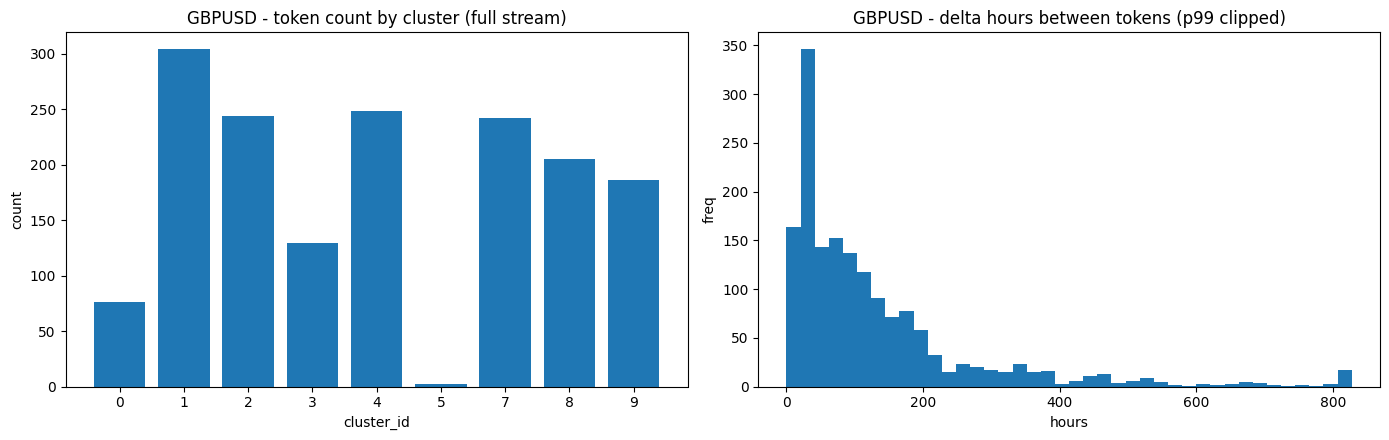

Done. Phase5 sequencing artifacts are ready in: ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2


In [9]:
# =========================
# Quick diagnostics
# =========================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

cnt = STREAM_FULL['cluster_id'].value_counts().sort_index()
axes[0].bar(cnt.index.astype(str), cnt.values)
axes[0].set_title(f'{SYMBOL} - token count by cluster (full stream)')
axes[0].set_xlabel('cluster_id')
axes[0].set_ylabel('count')

dt = STREAM_FULL['delta_prev_h'].clip(lower=0, upper=STREAM_FULL['delta_prev_h'].quantile(0.99))
axes[1].hist(dt, bins=40)
axes[1].set_title(f'{SYMBOL} - delta hours between tokens (p99 clipped)')
axes[1].set_xlabel('hours')
axes[1].set_ylabel('freq')

plt.tight_layout()
plt.show()

print('Done. Phase5 sequencing artifacts are ready in:', OUT_DIR)


## Output principal de esta etapa

- `token_stream_*`: cadena temporal de silabas con contexto local.
- `transition_matrix_*`: baseline de transiciones token -> token.
- `sequence_windows_*`: ventanas listas para transformer/context encoder.
- `token_vocabulary.json`: vocabulario final de tokens.